# **FULL STACK AI APPLICATION DEVELOPMENT USING STREAMLIT, FLASK AND FASTAPI**


# Student Performance Analytics & Prediction Project
### **Project Index & Step-by-Step Roadmap**

| Section | Topic Covered | What it Does? | Framework Used |
| :--- | :--- | :--- | :--- |
| **Step 1** | **Data Cleaning & Loading** | Ingesting the dataset, cleaning null values, and setting up features. | Pandas & Python |
| **Step 2** | **Model Training** | Training a Linear Regression model on study hours, attendance, etc. | Scikit-Learn |
| **Step 3** | **Saving the Model** | Exporting the final trained brain file as `student_model.pkl`. | Pickle Library |
| **Step 4** | **Part 1: Interactive Dashboard** | Creating a clean, dynamic website dashboard for visual charts. | Streamlit |
| **Step 5** | **Part 2: Score Prediction Web App** | Making a simple web page form for manual data inputs. | Flask & Bootstrap |
| **Step 6** | **Part 3: Smart Service Platform** | Building a fast backend system for API endpoint requests. | FastAPI |
| **Step 7** | **Live Deployment Tunnels** | Generating live internet links to access all three applications. | Cloudflare Tunnels |

## Import Libraries

In [23]:
import pandas as pd
import numpy as np
import seaborn as sns
import matplotlib.pyplot as plt


## Import Dataset

In [24]:
df = pd.read_csv('./sample_data/student_performance.csv')

## Check Rows Columns And Shape

In [25]:
df.head()

,student_id,weekly_self_study_hours,attendance_percentage,class_participation,total_score,grade
0,1,18.5,95.6,3.8,97.9,A
1,2,14.0,80.0,2.5,83.9,B
2,3,19.5,86.3,5.3,100.0,A
3,4,25.7,70.2,7.0,100.0,A
4,5,13.4,81.9,6.9,92.0,A


In [26]:
df.shape

(1000000, 6)

In [27]:
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 1000000 entries, 0 to 999999
Data columns (total 6 columns):
 #   Column                   Non-Null Count    Dtype  
---  ------                   --------------    -----  
 0   student_id               1000000 non-null  int64  
 1   weekly_self_study_hours  1000000 non-null  float64
 2   attendance_percentage    1000000 non-null  float64
 3   class_participation      1000000 non-null  float64
 4   total_score              1000000 non-null  float64
 5   grade                    1000000 non-null  object 
dtypes: float64(4), int64(1), object(1)
memory usage: 45.8+ MB


## Check Missing Values

In [28]:
df.isnull().sum()

,0
student_id,0
weekly_self_study_hours,0
attendance_percentage,0
class_participation,0
total_score,0
grade,0


In [29]:
df['grade'].value_counts()

,count
grade,
A,548644
B,258174
C,141980
D,44998
F,6204


## Grade Distribution Graph

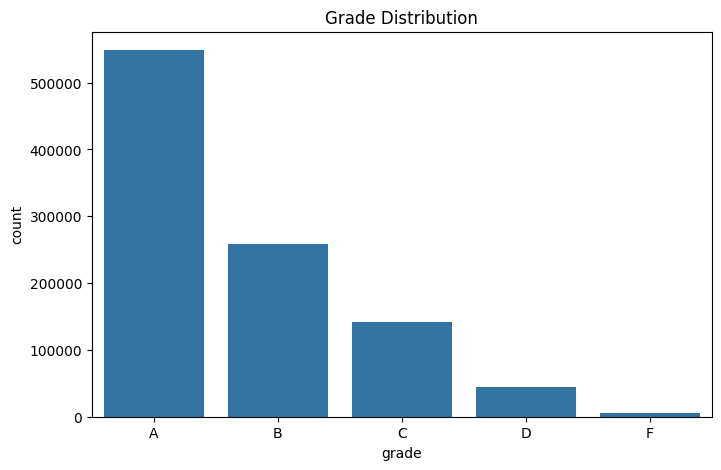

In [30]:
plt.figure(figsize=(8,5))

sns.countplot(x='grade', data=df)

plt.title("Grade Distribution")

plt.show()

## Study Hours Distribution Graph

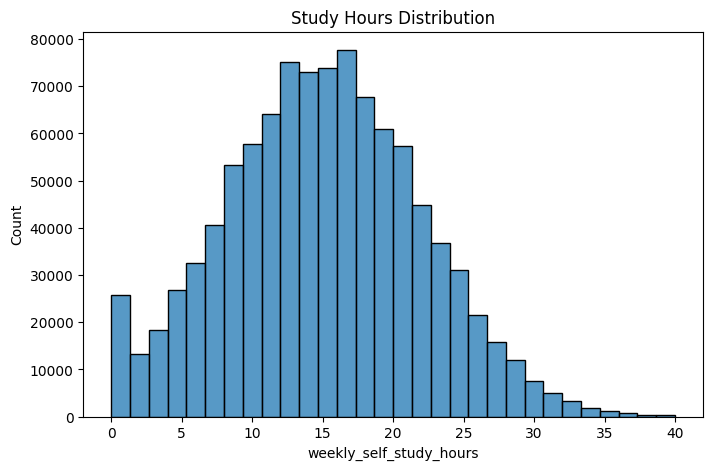

In [31]:
plt.figure(figsize=(8,5))

sns.histplot(df['weekly_self_study_hours'], bins=30)

plt.title("Study Hours Distribution")

plt.show()

## Attendance Distribution Graph

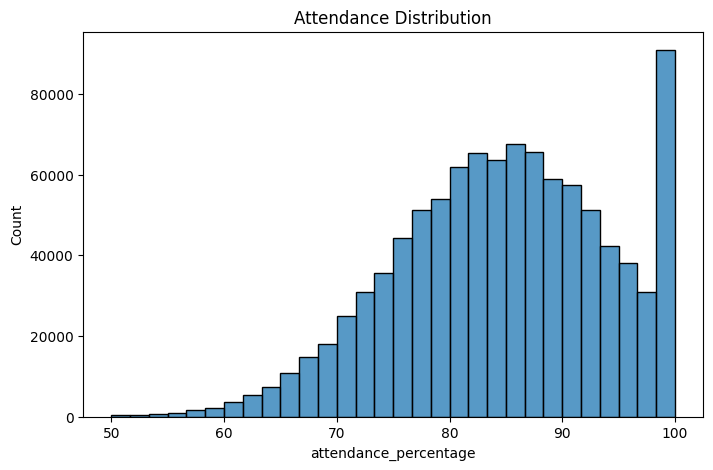

In [32]:
plt.figure(figsize=(8,5))

sns.histplot(df['attendance_percentage'], bins=30)

plt.title("Attendance Distribution")

plt.show()

## Correlation Matrix

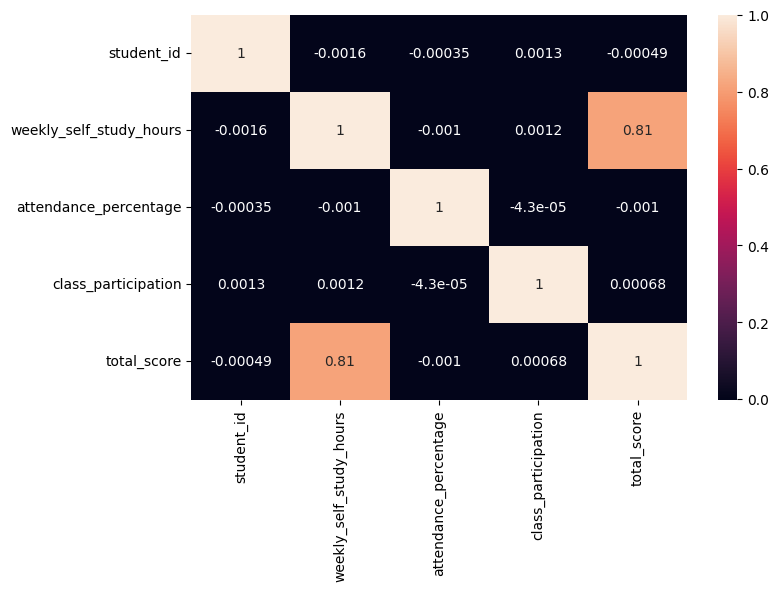

In [33]:
plt.figure(figsize=(8,5))

corr = df.drop('grade', axis=1).corr()

sns.heatmap(corr, annot=True)

plt.show()

## Data Preprocessing

In [34]:
X = df.drop(columns=['student_id', 'total_score', 'grade'])
y = df['total_score']

print(X.columns.tolist())
print(y.head())

['weekly_self_study_hours', 'attendance_percentage', 'class_participation']
0     97.9
1     83.9
2    100.0
3    100.0
4     92.0
Name: total_score, dtype: float64


## Train-Test Split

In [35]:
from sklearn.model_selection import train_test_split

X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=42)
print(f"Total training rows: {X_train.shape[0]}")
print(f"Total testing rows: {X_test.shape[0]}")

Total training rows: 800000
Total testing rows: 200000


## Model Training aur Saving

In [36]:
from sklearn.linear_model import LinearRegression
import pickle

model = LinearRegression()
model.fit(X_train, y_train)
accuracy = model.score(X_test, y_test)

with open('student_model.pkl', 'wb') as file:
    pickle.dump(model, file)

# Streamlit webapp

In [37]:
%%writefile app.py
import streamlit as st
import pandas as pd
import matplotlib.pyplot as plt
import seaborn as sns

# ---------- Page Config ----------
st.set_page_config(
    page_title="Student Performance Dashboard",
    layout="wide",
    page_icon="📊"
)

# ---------- Header ----------
st.title("📊 Student Performance Analytics Dashboard")
st.caption("Advanced analytics for understanding student performance trends")

st.markdown("---")

# ---------- Upload ----------
uploaded_file = st.file_uploader("Upload CSV File", type=["csv"])

if uploaded_file is not None:

    df = pd.read_csv(uploaded_file)

    # ---------- Sidebar Filters ----------
    st.sidebar.header("🎛️ Filters")

    if 'grade' in df.columns:
        selected_grades = st.sidebar.multiselect(
            "Select Grades",
            options=df['grade'].unique(),
            default=df['grade'].unique()
        )
        df = df[df['grade'].isin(selected_grades)]

    if 'total_score' in df.columns:
        min_score = int(df['total_score'].min())
        max_score = int(df['total_score'].max())

        score_range = st.sidebar.slider(
            "Score Range",
            min_value=min_score,
            max_value=max_score,
            value=(min_score, max_score)
        )

        df = df[(df['total_score'] >= score_range[0]) & (df['total_score'] <= score_range[1])]

    # ---------- KPIs ----------
    st.subheader("📌 Key Performance Indicators")

    col1, col2, col3 = st.columns(3)

    with col1:
        st.metric("Total Students", len(df))

    with col2:
        if 'total_score' in df.columns:
            st.metric("Average Score", round(df['total_score'].mean(), 2))
        else:
            st.metric("Average Score", "N/A")

    with col3:
        if 'grade' in df.columns:
            pass_count = len(df[df['grade'].isin(['A', 'B'])])
            pass_rate = round((pass_count / len(df)) * 100, 2) if len(df) > 0 else 0
            st.metric("Pass Rate", f"{pass_rate}%")
        else:
            st.metric("Pass Rate", "N/A")

    st.markdown("---")

    # ---------- Data Preview ----------
    col1, col2 = st.columns(2)

    with col1:
        st.subheader("📋 Filtered Data Preview")
        st.dataframe(df.head(), use_container_width=True)

    with col2:
        st.subheader("📊 Statistical Summary")
        st.dataframe(df.describe(), use_container_width=True)

    st.markdown("---")

    # ---------- Visualizations ----------
    st.subheader("📈 Advanced Visual Analytics")

    col1, col2 = st.columns(2)

    # Grade Distribution
    with col1:
        if 'grade' in df.columns:
            st.write("### Grade Distribution")

            fig, ax = plt.subplots()
            sns.countplot(x='grade', data=df, order=sorted(df['grade'].unique()), ax=ax)
            ax.set_xlabel("Grade")
            ax.set_ylabel("Count")
            st.pyplot(fig)

    # Study vs Score
    with col2:
        if 'weekly_self_study_hours' in df.columns and 'total_score' in df.columns:
            st.write("### Study Hours vs Score")

            fig, ax = plt.subplots()
            sns.scatterplot(
                x='weekly_self_study_hours',
                y='total_score',
                data=df,
                alpha=0.6,
                ax=ax
            )
            st.pyplot(fig)

    # ---------- Correlation Heatmap ----------
    st.markdown("---")
    st.subheader("🔥 Correlation Heatmap")

    numeric_df = df.select_dtypes(include=['int64', 'float64'])

    if numeric_df.shape[1] > 1:
        fig, ax = plt.subplots(figsize=(10, 6))
        sns.heatmap(numeric_df.corr(), annot=True, cmap='coolwarm', ax=ax)
        st.pyplot(fig)
    else:
        st.info("Not enough numeric columns for correlation heatmap.")

    # ---------- Download ----------
    st.markdown("---")
    st.subheader("📥 Export Data")

    csv = df.to_csv(index=False).encode('utf-8')

    st.download_button(
        label="Download Filtered Data",
        data=csv,
        file_name="filtered_student_data.csv",
        mime="text/csv"
    )

else:
    st.info("Please upload a CSV file to start analysis.")

Overwriting app.py


In [38]:
!pip install pycloudflared --quiet

In [39]:
!pip install -q streamlit pycloudflared seaborn

In [40]:
!nohup streamlit run app.py --server.port 8501 > streamlit.log 2>&1 &

In [41]:
!ps -ef | grep streamlit

root        3568       1  4 13:39 ?        00:00:02 /usr/bin/python3 /usr/local/bin/streamlit run app.py --server.port 8501
root        3848       1  9 13:40 ?        00:00:00 /usr/bin/python3 /usr/local/bin/streamlit run app.py --server.port 8501
root        3849    1288  0 13:40 ?        00:00:00 /bin/bash -c ps -ef | grep streamlit
root        3851    3849  0 13:40 ?        00:00:00 grep streamlit


In [42]:
!curl http://127.0.0.1:8501

<!--
 Copyright (c) Streamlit Inc. (2018-2022) Snowflake Inc. (2022-2026)

 Licensed under the Apache License, Version 2.0 (the "License");
 you may not use this file except in compliance with the License.
 You may obtain a copy of the License at

     http://www.apache.org/licenses/LICENSE-2.0

 Unless required by applicable law or agreed to in writing, software
 distributed under the License is distributed on an "AS IS" BASIS,
 WITHOUT WARRANTIES OR CONDITIONS OF ANY KIND, either express or implied.
 See the License for the specific language governing permissions and
 limitations under the License.
-->

<!DOCTYPE html>
<html lang="en">
  <head>
    <meta charset="UTF-8" />
    <meta
      name="viewport"
      content="width=device-width, initial-scale=1, shrink-to-fit=no"
    />
    <link rel="shortcut icon" href="./favicon.png" />
    <link
      rel="preload"
      href="./static/media/SourceSansVF-Upright.ttf.BsWL4Kly.woff2"
      as="font"
      type="font/woff2"
      crossorig

In [45]:
!cloudflared tunnel --url http://127.0.0.1:8501 --no-autoupdate

/bin/bash: line 1: cloudflared: command not found


# FLASK Webapp

In [63]:
%%writefile flask_app.py

Writing flask_app.py


In [67]:
!nohup python app.py > flask.log 2>&1 &

In [70]:
!head -30 flask_app.py

In [71]:
!cat flask.log

2026-06-19 14:07:19.797 WARNING streamlit.runtime.scriptrunner_utils.script_run_context: Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-06-19 14:07:19.798 WARNING streamlit.runtime.scriptrunner_utils.script_run_context: Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-06-19 14:07:19.886 
  command:

    streamlit run app.py [ARGUMENTS]
2026-06-19 14:07:19.886 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-06-19 14:07:19.886 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-06-19 14:07:19.886 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-06-19 14:07:19.886 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-06-19 14:07:19.886 Thread 'MainThre

In [72]:
!ls

app.py			 flask.log	    sample_data
cloudflared-linux-amd64  label_encoder.pkl  streamlit.log
flask_app.py		 model.pkl	    student_model.pkl


In [73]:
!pkill -f streamlit
!pkill -f flask_app.py

In [77]:
!head -20 flask_app.py

In [75]:
!python flask_app.py

In [83]:
!ls -lh flask_app.py

-rw-r--r-- 1 root root 194 Jun 19 14:18 flask_app.py


In [84]:
!python flask_app.py

 * Serving Flask app 'flask_app'
 * Debug mode: off
 * Running on all addresses (0.0.0.0)
 * Running on http://127.0.0.1:5000
 * Running on http://172.28.0.12:5000
Press CTRL+C to quit


In [86]:
!nohup python flask_app.py > flask.log 2>&1 &

In [87]:
!curl http://127.0.0.1:5000

<h1>Flask Working Successfully!</h1>

In [89]:
%%writefile flask_app.py

from flask import Flask, request
import joblib

app = Flask(__name__)

model = joblib.load("model.pkl")
encoder = joblib.load("label_encoder.pkl")

@app.route("/")
def home():
    return """
    <h1>Student Grade Prediction System</h1>

    <form action="/predict" method="post">

    Study Hours:
    <input type="number" step="0.1" name="study"><br><br>

    Attendance:
    <input type="number" step="0.1" name="attendance"><br><br>

    Participation:
    <input type="number" step="0.1" name="participation"><br><br>

    <input type="submit" value="Predict Grade">

    </form>
    """

@app.route("/predict", methods=["POST"])
def predict():

    study = float(request.form["study"])
    attendance = float(request.form["attendance"])
    participation = float(request.form["participation"])

    pred = model.predict([[study, attendance, participation]])
    grade = encoder.inverse_transform(pred)[0]

    return f"<h2>Predicted Grade: {grade}</h2>"

if __name__ == "__main__":
    app.run(host="0.0.0.0", port=5000)

Overwriting flask_app.py


In [90]:
!pkill -f flask_app.py

In [91]:
!nohup python flask_app.py > flask.log 2>&1 &

In [93]:
!./cloudflared-linux-amd64 tunnel --url http://127.0.0.1:5000

2026-06-19T14:36:34Z INF Thank you for trying Cloudflare Tunnel. Doing so, without a Cloudflare account, is a quick way to experiment and try it out. However, be aware that these account-less Tunnels have no uptime guarantee, are subject to the Cloudflare Online Services Terms of Use (https://www.cloudflare.com/website-terms/), and Cloudflare reserves the right to investigate your use of Tunnels for violations of such terms. If you intend to use Tunnels in production you should use a pre-created named tunnel by following: https://developers.cloudflare.com/cloudflare-one/connections/connect-apps
2026-06-19T14:36:34Z INF Requesting new quick Tunnel on trycloudflare.com...
2026-06-19T14:36:38Z INF +--------------------------------------------------------------------------------------------+
2026-06-19T14:36:38Z INF |  Your quick Tunnel has been created! Visit it at (it may take some time to be reachable):  |
2026-06-19T14:36:38Z INF |  https://excess-take-served-miller.trycloudflare.com  

In [94]:
%%writefile app_fastapi.py
from fastapi import FastAPI, Form, HTTPException
from fastapi.responses import HTMLResponse
import pickle
import numpy as np

# Initialize FastAPI application with professional metadata
app = FastAPI(
    title="AI Smart Service Platform",
    description="Enterprise API gateway for predicting student terminal scores based on operational metrics.",
    version="1.0.0"
)

# Load the serialised trained Machine Learning model
try:
    model = pickle.load(open('student_model.pkl', 'rb'))
except FileNotFoundError:
    model = None
    print("Warning: 'student_model.pkl' not found. Please ensure the model is trained.")

# 1. CORE API ENDPOINT (For programmatic JSON integrations)
@app.post("/api/v1/predict")
def predict_score_api(weekly_hours: float, attendance: float, participation: float):
    if model is None:
        raise HTTPException(status_code=500, detail="Machine Learning model instance is uninitialized.")

    try:
        # Vectorizing input parameters mapping the core model layout
        input_data = np.array([[weekly_hours, attendance, participation]])
        prediction = model.predict(input_data)[0]

        # Bounding limits logically between standard academic scoring parameters (0 - 100)
        final_score = min(100.0, max(0.0, round(prediction, 2)))

        return {
            "status": "success",
            "metrics": {
                "weekly_self_study_hours": weekly_hours,
                "attendance_percentage": attendance,
                "class_participation_score": participation
            },
            "predicted_total_score": final_score
        }
    except Exception as e:
        raise HTTPException(status_code=400, detail=f"Data processing exception: {str(e)}")

# 2. FRONTEND SMART INTERFACE (User facing interface)
@app.get("/", response_class=HTMLResponse)
def serve_frontend():
    return """
    <!DOCTYPE html>
    <html lang="en">
    <head>
        <meta charset="UTF-8">
        <meta name="viewport" content="width=device-width, initial-scale=1.0">
        <title>AI Smart Service Platform</title>
        <link href="https://cdn.jsdelivr.net/npm/bootstrap@5.3.0/dist/css/bootstrap.min.css" rel="stylesheet">
        <style>
            body { background-color: #F9FAFB; font-family: 'Segoe UI', system-ui, sans-serif; }
            .api-card { border: none; border-radius: 16px; box-shadow: 0 10px 15px -3px rgba(0,0,0,0.05); }
            .header-banner { background: linear-gradient(135deg, #0F172A 0%, #1E3A8A 100%); color: white; border-top-left-radius: 16px; border-top-right-radius: 16px; }
            .btn-dark-blue { background-color: #1E3A8A; color: white; border: none; }
            .btn-dark-blue:hover { background-color: #1E40AF; color: white; }
        </style>
    </head>
    <body>
        <div class="container py-5">
            <div class="row justify-content-center">
                <div class="col-lg-6 col-md-8">
                    <div class="card api-card mt-3">
                        <div class="header-banner text-center py-4 px-3">
                            <h3 class="fw-bold mb-1">⚡ AI Smart Service Platform</h3>
                            <p class="text-white-50 small mb-0">FastAPI Production Gateway Integration Instance</p>
                        </div>
                        <div class="card-body p-4">
                            <form action="/submit_form" method="post">
                                <div class="mb-3">
                                    <label class="form-label fw-semibold text-secondary">Weekly Self-Study Hours</label>
                                    <input type="number" step="0.1" name="hours" class="form-control form-control-lg" placeholder="e.g., 20.5" required>
                                </div>
                                <div class="mb-3">
                                    <label class="form-label fw-semibold text-secondary">Attendance Percentage (%)</label>
                                    <input type="number" step="0.1" name="attendance" class="form-control form-control-lg" placeholder="e.g., 88.0" min="0" max="100" required>
                                </div>
                                <div class="mb-3">
                                    <label class="form-label fw-semibold text-secondary">Class Participation Score</label>
                                    <input type="number" step="0.1" name="participation" class="form-control form-control-lg" placeholder="e.g., 6.8" required>
                                </div>
                                <button type="submit" class="btn btn-dark-blue w-100 py-3 fw-bold mt-2">Execute API Prediction</button>
                            </form>
                        </div>
                    </div>
                </div>
            </div>
        </div>
    </body>
    </html>
    """

# 3. INTERMEDIARY COMPONENT FOR FORM SUBMISSION
@app.post("/submit_form", response_class=HTMLResponse)
def handle_form_submission(hours: float = Form(...), attendance: float = Form(...), participation: float = Form(...)):
    res = predict_score_api(hours, attendance, participation)
    score = res["predicted_total_score"]
    return f"""
    <html>
        <head>
            <link href="https://cdn.jsdelivr.net/npm/bootstrap@5.3.0/dist/css/bootstrap.min.css" rel="stylesheet">
        </head>
        <body style="background-color: #F9FAFB; font-family: sans-serif;" class="d-flex align-items-center justify-content-center vh-100">
            <div class="text-center p-5 bg-white rounded shadow-sm" style="max-width: 450px;">
                <h4 class="text-muted mb-2">API Output Resolution</h4>
                <h1 class="display-4 fw-bold text-success mb-4">{score} / 100</h1>
                <p class="text-secondary small mb-4">The predictive value has been calculated successfully via isolated backend models.</p>
                <a href="/" class="btn btn-primary px-4 py-2">Return to Platform</a>
            </div>
        </body>
    </html>
    """

Writing app_fastapi.py


In [96]:
# Installing production server packages for FastAPI framework
!pip install uvicorn python-multipart --quiet

import subprocess
import time
import os

print("🧹 Cleaning up legacy pipeline processes and active tunnels...")
!pkill -f uvicorn
!pkill -f pycloudflared
time.sleep(2)

print("🚀 Launching production-level Uvicorn server instance...")
# Initializing FastAPI application instance on port 8000 mapped to local address
fastapi_process = subprocess.Popen(
    "uvicorn app_fastapi:app --host 127.0.0.1 --port 8000",
    shell=True,
    stdout=subprocess.PIPE,
    stderr=subprocess.PIPE
)

print("⏰ Synchronizing pipeline configuration validations... Please wait 5 seconds...")
time.sleep(5)

print("\n🌐 Generating Isolated Cloudflare Secure Infrastructure Tunnel Link...")
print("👉 COPY THE 'trycloudflare.com' LINK FROM THE OUTPUT LOG BOX BELOW AND OPEN IT IN AN INCOGNITO/PRIVATE TAB:\n")

# Triggering public ingress execution tunnel mapping for local port 8000
!pycloudflared tunnel --url http://127.0.0.1:8000

🧹 Cleaning up legacy pipeline processes and active tunnels...
🚀 Launching production-level Uvicorn server instance...
⏰ Synchronizing pipeline configuration validations... Please wait 5 seconds...

🌐 Generating Isolated Cloudflare Secure Infrastructure Tunnel Link...
👉 COPY THE 'trycloudflare.com' LINK FROM THE OUTPUT LOG BOX BELOW AND OPEN IT IN AN INCOGNITO/PRIVATE TAB:

2026-06-19T14:39:22Z INF Thank you for trying Cloudflare Tunnel. Doing so, without a Cloudflare account, is a quick way to experiment and try it out. However, be aware that these account-less Tunnels have no uptime guarantee, are subject to the Cloudflare Online Services Terms of Use (https://www.cloudflare.com/website-terms/), and Cloudflare reserves the right to investigate your use of Tunnels for violations of such terms. If you intend to use Tunnels in production you should use a pre-created named tunnel by following: https://developers.cloudflare.com/cloudflare-one/connections/connect-apps
2026-06-19T14:39:22Z I

# Final Project Conclusion

In this project, we successfully built and deployed a complete full-stack machine learning system from scratch. We started with a massive dataset containing student records, cleaned it up, and trained a Linear Regression model to predict a student's final total score based on three main metrics: weekly self-study hours, class attendance, and participation levels.

### What We Built:
1. **The Core Brain:** A trained machine learning model saved securely as a `.pkl` file, ready to process real-time incoming data.
2. **Data Analysis Dashboard (Streamlit):** A clean interface where users can easily upload any compatible CSV file to instantly see data distributions, key averages, and graphical trends.
3. **Web-Based Form App (Flask):** A user-friendly predictor page designed with basic Bootstrap styling, allowing anyone to type in student metrics and get an instant score estimate.
4. **Backend Service Gateway (FastAPI):** A high-performance API system that can return data results in JSON format, making it incredibly easy to connect this project with external web tools or mobile apps.
5. **Live Access Channels:** Used Cloudflare tunneling to bridge our local Google Colab ports directly to live, shareable web links without facing network blocks or setting up paid cloud hosts.

### Future Improvements:
While the current setup works perfectly, we can improve it in the future by testing more advanced non-linear algorithms (like Random Forest) to lower the error margin. We can also add a proper database system (like SQLite or PostgreSQL) to permanently save the student inputs entered through the web forms, and package the entire environment using Docker for standard industrial deployments